Regression fit for different correlations - coding

Reading Material: Before addressing this exercise, we recommend that you study Linear least
squares regression models.

Code Reference: Become familiar with script s_ols_regression_lfm that illustrates the regression LFM
for a univariate target variable and one observable factor.

Consider a regression linear factor model for a univariate target variable X(n_bar = 1) and one exogenous factor
 Z(k_bar = 1) with joint scenario-probability distribution and uniform probabilities, p(j) = 1/j

Assume that the scenarios are j_bar = 10^4 Monte Carlo simulations from a jointly normal distribution
with parameters as follows

where gamma, x, z is an arbitrary parameter in (-1,1).

In [26]:
from numpy import array, ones, sqrt
from scipy.stats import multivariate_normal
from seaborn import lineplot, scatterplot
import matplotlib.pyplot as plt

Task 1

Generate the joint scenarios for (X, Z).

Scenarios and their moments.

In [27]:
######################### inputs #########################
 # joint expectation - 2D array - both variables are described as 1 vector (X,Z), because we care
 # how they move together
 # holding the true means of the 2 variables
 # E{X} = 1, for target X, the thing I want to explain (the stock's return)
 # E{Z} = 2, for the factor Z, the thing I want to explain (with the market's return)
 # true mean of X,Z
mu_xz = array([[1, 2]])

# arbitrary parameter - we swap this value out for task 5 comparison (0.9, -0.2)
# noting the residual variance for each run
rho_xz = 0.9

# true joint covariance ([variance, covariance*0.9], [covariance*0.9, variance])
sigma2_xz = array([[4, 6*rho_xz],
                   [6*rho_xz, 9]])
# number of Monte Carlo simulations
j_bar = 10000

# equal probabilities for each scenario,  10,000 values of 0.0001  which summed together gives '1'
p = ones(j_bar)/j_bar
##########################################################

# the joint scenarios of 'X' and 'Z'

# it has a shape of (10000, 2): col 0 = X, col 1 = Z
# mu_xz[0] hands over the whole first row (a flat mean vector), keeping mu_xz 1D -> values [1, 2]
# rvs draws random variates/samples from the normal distribution with the mean and covariance that is given.
xz = multivariate_normal.rvs(mu_xz[0], sigma2_xz, j_bar)

# expectation of joint scenarios
# probability-weighted mean, estimated mean of X,Z
# using '@' to carry out matrix multiplication - multiplying each scenarios value by its probability
# sums down each column
m_xz = p @ xz

# estimated covariance of joint scenarios
# sum p_j (x_j - m)(x_j - m)'
# xz - m_xz -> centres the data by subtracting each columns mean from every row
# .T Transposes so it can be matrix multiplied against itself
# * pElement wise multiplication  of each scenario by its weights
# @ (xz - m_xz) sums the weighted products over all 10,000 scenarios
s2_xz = ((xz - m_xz).T * p) @ (xz - m_xz)

############ results ############
print('m_xz =', m_xz.round(6))
print()
print('s2_xz \n', s2_xz.round(6))

m_xz = [0.991551 1.997881]

s2_xz 
 [[4.019792 5.421618]
 [5.421618 9.057282]]


Task 2

Compute the regression coefficients alpha and beta. Building α and β from the measured moments
(not the true ones).

In Trading 'alpha' normally means excess return that the market doesnt explain.
Here alpha is the intercept that positions the line

In [28]:
# loading
# Cov(X,Z) ~ 5.4
# Var(Z) ~ 9
# Cov(X,Z)/Var(Z) ~ = 5.4/9 = 0.6
# market beta - when the market rises 1% the stock rises 0.6%
beta = s2_xz[0, 1] / s2_xz[1, 1]

# shift (intercept)
# E{X} - β E{Z}
# m_xz[0] -> estimated mean of the target
# m_xz[1] -> estimated mean of the factor
alpha = m_xz[0] - beta * m_xz[1]

# These values are needed because the regression line always passes through the point of averages (E{X}, E{Z})

# E{X} = alpha + Beta.E{Z}

print('alpha = ', alpha.round(6))
print()
print('beta = ', beta.round(6))

alpha =  -0.204365

beta =  0.598592


Task 3

Plot the scenarios {(x^{j}, z^{j})} j_bar, j=1, superimposing the regression line x = α and βz.

We draw every simulated Z,X scenario as a dot, then draw the straight line from α + βz(Task 2) through them.

To see the best fit line passing through the cloud of dots, and to see how far the dots are from the line.
How much of X the factor Z does not explain.

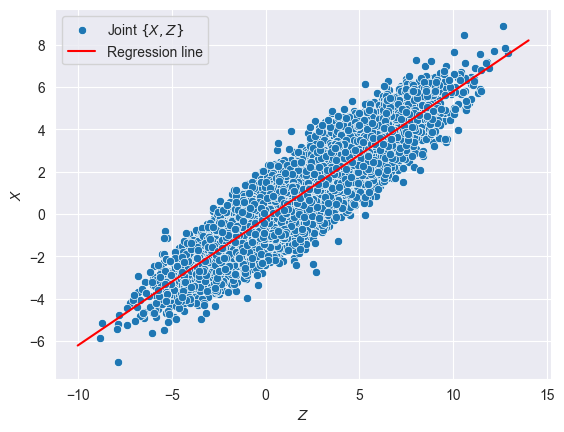

In [29]:
# the regression prediction line of X,
# function: to give back the fitted line
x_reg = lambda z_grid: alpha + beta * z_grid

# The mean of Z spanning 4 std deviations (left and right of line)
z_grid = array([m_xz[1] - 4 * sqrt(s2_xz[1, 1]), m_xz[1] + 4 * sqrt(s2_xz[1, 1])])

# joint scenarios with regression line
# xz[:, 1] -> column 1 of the joint scenarios - all 10,000 values simulated Z vertical positions
# xz[:, 0] -> column 0 of the joint scenarios - all 10,000 values simulated X horizontal positions
# z_grid -> z = factor, grid = a set of points along the grid
# x_reg(z_grid) -> prediction evaluated at the grid points
scatterplot(x=xz[:, 1], y=xz[:, 0], label='Joint $\\{X,Z\\}$')
# passing the x_reg function to the lineplot to return the fitted line values
lineplot(x=z_grid, y=x_reg(z_grid), c='r', label='Regression line').set(xlabel='$Z$', ylabel='$X$');

Task 4

Compute the variance of the Residual.

Residual Variance.

In [30]:
# Residual
# unexplained / epsilon
# what is left of X after the line (α + βz) has been calculated
# xz[:, 0] -> actual X value in each scenario
# x_reg(xz[:, 1]) -> using the x_reg function to get the values of the fitted line
u = xz[:, 0] - x_reg(xz[:, 1])

# measured the probability-weighted-mean of U
# ~= 0, which OLS guarantees by construction
m_u = p @ u

# measured variance of U
# u - m_u -> centres the residuals
# **2 squares each one, so gaps above and below the line both count towards +ve and big misses
# p @ takes the probability weighted average
s2_u = p @ (u - m_u)**2

###### results -> The average miss off the line ######
print('s2_u =', s2_u.round(6))

s2_u = 0.774453


  rho    alpha     beta     s2_u   theory     R2
  0.9  -0.2081   0.6005   0.7495   0.7600  0.816
 -0.2   1.2914  -0.1386   3.7940   3.8400  0.044


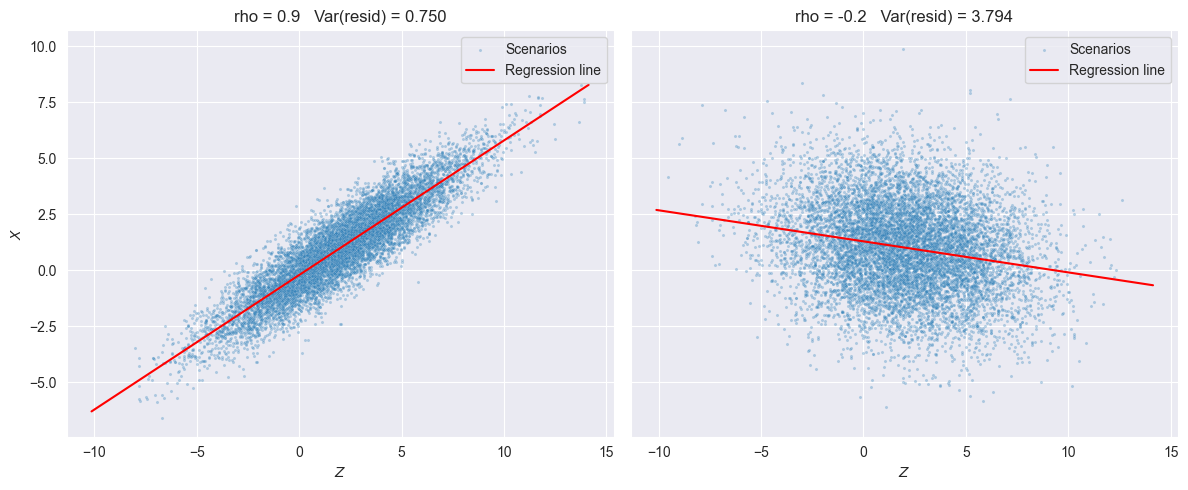

In [31]:
########## COMPARISON Code Cell for: rho = 0.9 vs rho = -0.2 ##########
fig, axes = plt.subplots(1, 2, figsize=(12, 5), sharex=True, sharey=True)
results = []

for ax, rho in zip(axes, [0.9, -0.2]):
    # Task 1: scenarios and their moments
    sigma2 = array([[4, 6*rho], [6*rho, 9]])
    xz_r = multivariate_normal.rvs(mu_xz[0], sigma2, j_bar, random_state=42)
    m_r = p @ xz_r
    s2_r = ((xz_r - m_r).T * p) @ (xz_r - m_r)
    # Task 2: regression coefficients
    beta_r = s2_r[0, 1]/s2_r[1, 1]
    alpha_r = m_r[0] - beta_r*m_r[1]
    # Task 4: residual variance
    u_r = xz_r[:, 0] - (alpha_r + beta_r*xz_r[:, 1])
    s2_u_r = p @ (u_r - p @ u_r)**2
    results.append((rho, alpha_r, beta_r, s2_u_r, 4*(1 - rho**2), 1 - s2_u_r/s2_r[0, 0]))
    # Task 3: plot
    z_grid_r = array([m_r[1] - 4*sqrt(s2_r[1, 1]), m_r[1] + 4*sqrt(s2_r[1, 1])])
    scatterplot(x=xz_r[:, 1], y=xz_r[:, 0], s=5, alpha=0.3, ax=ax, label='Scenarios')
    lineplot(x=z_grid_r, y=alpha_r + beta_r*z_grid_r, c='r', ax=ax, label='Regression line')
    ax.set(title=f'rho = {rho}   Var(resid) = {s2_u_r:.3f}', xlabel='$Z$', ylabel='$X$')

print(f"{'rho':>5} {'alpha':>8} {'beta':>8} {'s2_u':>8} {'theory':>8} {'R2':>6}")
for r in results:
    print(f"{r[0]:>5} {r[1]:>8.4f} {r[2]:>8.4f} {r[3]:>8.4f} {r[4]:>8.4f} {r[5]:>6.3f}")
plt.tight_layout()
plt.show()

Task 5

Compare the residual variance obtained for  gamma,x,z = -0.2 and for gamma,x,z = 0.9, giving
the interpretation to the results.

With rho = 0.9 the residual variance (= 0.76) is far less than with gamma = -0.2 (=3.8).

Being Monte-Carlo estimates, these vary slightly between runs.

In the normal case Var(Epsilon) = sigma2_X(1 - rho2), so the residual variance depends only on |rho|
not its sign.

A strong correlation means Z explains about 81% of X's variance (R2 = rho2), leaving little unexplained
noise.

A weak correlation explains only 4%, so the regression line fits poorly and the residual variance stays
close to Var(X) = 4.

Finance takeaway: This is why a stock with a high correlation to the market has most of its risk as
'market risk', while a low correlation stock is mostly idiosyncratic risk.
That's the same split the factor models in Unit 3-4 were making.

  rho    alpha     beta     s2_u   theory     R2
  0.9  -0.2081   0.6005   0.7495   0.7600  0.816
 -0.2   1.2914  -0.1386   3.7940   3.8400  0.044


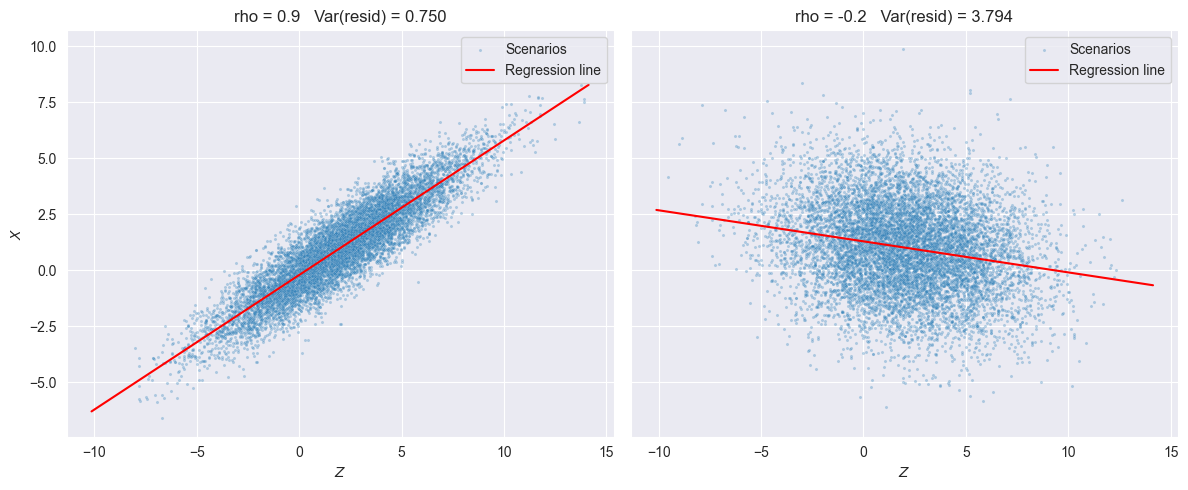

In [32]:
import matplotlib.pyplot as plt

########## comparison: rho = 0.9 vs rho = -0.2 ##########
fig, axes = plt.subplots(1, 2, figsize=(12, 5), sharex=True, sharey=True)
results = []

for ax, rho in zip(axes, [0.9, -0.2]):
    # Task 1: scenarios and their moments
    sigma2 = array([[4, 6*rho], [6*rho, 9]])
    xz_r = multivariate_normal.rvs(mu_xz[0], sigma2, j_bar, random_state=42)
    m_r = p @ xz_r
    s2_r = ((xz_r - m_r).T * p) @ (xz_r - m_r)
    # Task 2: regression coefficients
    beta_r = s2_r[0, 1]/s2_r[1, 1]
    alpha_r = m_r[0] - beta_r*m_r[1]
    # Task 4: residual variance
    u_r = xz_r[:, 0] - (alpha_r + beta_r*xz_r[:, 1])
    s2_u_r = p @ (u_r - p @ u_r)**2
    results.append((rho, alpha_r, beta_r, s2_u_r, 4*(1 - rho**2), 1 - s2_u_r/s2_r[0, 0]))
    # Task 3: plot
    z_grid_r = array([m_r[1] - 4*sqrt(s2_r[1, 1]), m_r[1] + 4*sqrt(s2_r[1, 1])])
    scatterplot(x=xz_r[:, 1], y=xz_r[:, 0], s=5, alpha=0.3, ax=ax, label='Scenarios')
    lineplot(x=z_grid_r, y=alpha_r + beta_r*z_grid_r, c='r', ax=ax, label='Regression line')
    ax.set(title=f'rho = {rho}   Var(resid) = {s2_u_r:.3f}', xlabel='$Z$', ylabel='$X$')

print(f"{'rho':>5} {'alpha':>8} {'beta':>8} {'s2_u':>8} {'theory':>8} {'R2':>6}")
for r in results:
    print(f"{r[0]:>5} {r[1]:>8.4f} {r[2]:>8.4f} {r[3]:>8.4f} {r[4]:>8.4f} {r[5]:>6.3f}")
plt.tight_layout()
plt.show()